# 0 Setup

In [2]:
from pathlib import Path
import sys

repo_path = Path.cwd().resolve()
if repo_path.name == 'notebooks':
    repo_path = repo_path.parent
sys.path.insert(0, str(repo_path))

from src.config import SAMPLE_SUBMISSION, TEST_RAW, TRAIN_RAW, repo_root

print(f'Repository root: {repo_root()}')
for raw_path in (TRAIN_RAW, TEST_RAW, SAMPLE_SUBMISSION):
    print(f'{raw_path.name} exists: {raw_path.exists()}')

Repository root: C:\Users\SKY\Documents\Pink Ai
pinkai_train.csv exists: True
pinkai_test.csv exists: True
sample_submission.csv exists: True


# 1 Load and inspect

Load both raw files as text, preserving cell values.

In [3]:
from IPython.display import display

from src.load import load_test, load_train
from src.inspect_data import (
    category_values,
    comma_decimal_count,
    date_samples,
    empty_cell_counts,
    id_report,
    label_counts,
    measurement_columns,
    non_numeric_cells,
    numeric_ranges,
    odd_column_names,
    shape_summary,
)

train = load_train()
test = load_test()
measurement_cols = measurement_columns(train)["column"].tolist()
print(f"Loaded train: {train.shape}; test: {test.shape}; measurement columns: {len(measurement_cols)}")

Loaded train: (9000, 38); test: (3000, 37); measurement columns: 30


Compare row and column counts and file-specific columns.

In [4]:
display(shape_summary(train, test))

{'train_shape': (9000, 38),
 'test_shape': (3000, 37),
 'train_only_columns': ['diagnosis'],
 'test_only_columns': []}

List column names that do not match lowercase letters and underscores.

In [5]:
print("Train odd column names")
display(odd_column_names(train))

Train odd column names


,column_name
0,Texture_Mean
1,perimeter mean
2,concave points_se
3,AREA_WORST


Count each raw diagnosis spelling in the training file.

In [6]:
display(label_counts(train).head(15))

,raw_value,count
0,benign,1078
1,Benign,1074
2,B,1066
3,0,1020
4,B,979
5,M,740
6,1,700
7,malignant,627
8,MALIGNANT,626
9,m,618


Count blank, whitespace-only, and literal nan cells by column.

In [7]:
print("Train empty-like cells")
display(empty_cell_counts(train).head(15))

Train empty-like cells


,column,empty_count,empty_percent
0,notes,4297,47.744444
1,smoothness_se,539,5.988889
2,smoothness_mean,534,5.933333
3,smoothness_worst,528,5.866667
4,AREA_WORST,298,3.311111
5,compactness_worst,295,3.277778
6,fractal_dimension_mean,294,3.266667
7,symmetry_worst,289,3.211111
8,fractal_dimension_se,283,3.144444
9,texture_worst,282,3.133333


Count measurement cells written with comma decimal separators.

In [9]:
print("Train comma-decimal counts")
display(comma_decimal_count(train, measurement_cols).head(15))

Train comma-decimal counts


,column,comma_decimal_count
0,radius_mean,324
1,Texture_Mean,332
2,perimeter mean,297
3,area_mean,317
4,smoothness_mean,314
5,compactness_mean,360
6,concavity_mean,331
7,concave_points_mean,345
8,symmetry_mean,300
9,fractal_dimension_mean,338


Count unparseable non-empty measurement values and show examples.

In [8]:
print("Train non-numeric measurement values")
display(non_numeric_cells(train, measurement_cols).head(15))

Train non-numeric measurement values


,column,non_numeric_count,example_bad_values
0,radius_mean,142,"[n/a, ?, NULL, missing, unknown]"
1,Texture_Mean,163,"[?, N/A, n/a, unknown, --]"
2,perimeter mean,154,"[unknown, -, --, NULL, n/a]"
3,area_mean,680,"[1,419.5, 1,067.1, 1,310.0, 1,041.0, 1,062.7]"
4,smoothness_mean,161,"[missing, n/a, N/A, unknown, NULL]"
5,compactness_mean,159,"[NULL, unknown, N/A, missing, -]"
6,concavity_mean,156,"[missing, unknown, N/A, -, n/a]"
7,concave_points_mean,172,"[NULL, n/a, N/A, -, --]"
8,symmetry_mean,171,"[NULL, unknown, -, N/A, --]"
9,fractal_dimension_mean,198,"[-, ?, n/a, missing, N/A]"


Report repeated IDs, exact duplicate rows, unique IDs, and train-test overlap.

In [10]:
display(id_report(train, test))

{'train_duplicate_patient_id_rows': 346,
 'test_duplicate_patient_id_rows': 116,
 'train_identical_duplicate_rows': 173,
 'test_identical_duplicate_rows': 58,
 'train_unique_patient_ids': 8654,
 'test_unique_patient_ids': 2884,
 'shared_patient_ids': [],
 'shared_patient_id_count': 0}

Show raw values of center and biopsy_followup_code in both files.

In [11]:
for column in ("center", "biopsy_followup_code"):
    print(f"Train {column}")
    display(category_values(train, column).head(15))

Train center


,raw_value,count
0,Site A,3308
1,Site B,2835
2,Site C,1977
3,SITE A,166
4,SITE B,149
5,SITE C,85
6,Site B,36
7,Site A,35
8,Site C,32
9,Site A,31


Train biopsy_followup_code


,raw_value,count
0,ROUTINE,5362
1,ONC-REF,3449
2,RECHECK,189


Sample raw exam dates reproducibly from each file.

In [12]:
print("Train exam_date sample")
display(date_samples(train, n=15))

Train exam_date sample


,exam_date
0,17/09/2025
1,13-Apr-26
2,30-Nov-25
3,2026-06-06
4,"November 13, 2025"
5,2026-06-15
6,12-Nov-25
7,2025-05-02
8,16/01/2026
9,27-May-25


List measurement columns and inspect training numeric ranges for unusual units.

In [13]:
print(f"Measurement columns ({len(measurement_cols)})")
print(measurement_cols)
display(numeric_ranges(train, measurement_cols).head(15))

Measurement columns (30)
['radius_mean', 'Texture_Mean', 'perimeter mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'AREA_WORST', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']


,column,min,p01,median,p99,max
0,radius_mean,0.500000,1.057204,13.341250,24.912284,2.030953e+04
1,Texture_Mean,9.468410,11.139467,18.892800,31.972451,2.916305e+04
2,perimeter mean,32.761600,53.484908,89.230000,736.136000,5.603466e+05
3,area_mean,-452.200000,84.506000,551.500000,1830.861000,1.272592e+06
4,smoothness_mean,0.052706,0.068676,0.095923,0.139117,1.159700e+02
5,compactness_mean,0.014003,0.033932,0.095090,0.284765,2.846800e+02
6,concavity_mean,0.000000,0.000000,0.071199,0.391361,3.175000e+02
7,concave_points_mean,0.000000,0.000000,0.037408,0.182826,1.640000e+02
8,symmetry_mean,0.094759,0.129867,0.179513,0.266970,2.067900e+02
9,fractal_dimension_mean,0.046436,0.051028,0.061602,0.090196,7.408310e+01


## What we saw

### 1. Size and structure
- Train has 9,000 rows and 38 columns. Test has 3,000 rows and 37 columns. The only column test lacks is `diagnosis` (the answer), which is correct.
- 30 columns are the real measurements (10 properties x mean / se / worst). The other columns are admin: `patient_id`, `exam_date`, `center`, `age`, `biopsy_followup_code`, `notes`, `sample_ref`.
- Four column names are inconsistent: `Texture_Mean`, `perimeter mean`, `concave points_se`, `AREA_WORST`. Same problem in train and test. We rename everything to lowercase_with_underscores.

### 2. The answer column (`diagnosis`) is written many ways
- Benign appears as `B`, ` B`, `Benign`, `benign `, `0` and more. Malignant appears as `M`, `m`, `MALIGNANT`, `malignant`, `1` and more.
- The top 10 spellings cover about 8,500 of the 9,000 rows, so a few rarer spellings are hidden further down. We must check them all when we clean.
- Roughly 4 in 10 patients are malignant, 6 in 10 benign. This is not extremely imbalanced.

### 3. Numbers are stored as messy text
- **Comma as decimal point:** `1,02967` means 1.02967. It appears in hundreds of cells in almost every measurement column (e.g. 360 in `compactness_mean`).
- **Comma as thousands separator:** `1,419.5` in `area_mean` means 1419.5. This is the OPPOSITE meaning of the comma! If we blindly replace "," with ".", we break these (it becomes `1.419.5`). Rule needed: if a value contains both a comma and a dot, remove the comma; if it has only a comma, treat it as the decimal point.
- **Fake missing values:** `n/a`, `?`, `NULL`, `missing`, `unknown`, `-`, `--`. All of these must become real missing values (NaN).

### 4. Missing values
- `smoothness_mean`, `smoothness_se`, `smoothness_worst` are each missing in about 6% of rows, the highest among measurements. Other measurements have fewer gaps.
- `notes` is empty in about 48% of rows (both files) and also contains both English and Arabic text.
- Missing values will be filled using training-file statistics only (never test).

### 5. Impossible and wrong-unit values (the "wrong units" trap)
- Normal `area_mean` is around 550 (median) and 99% of values are below about 1,830. But the maximum is 1,272,592 and the minimum is NEGATIVE (-452). Area cannot be negative.
- `radius_mean`: median 13.3, maximum 20,309. `perimeter mean`: median 89, maximum 560,346.
- So some rows were recorded in a different unit (values hugely too big), and some have sign errors. Plan: use the geometry link (perimeter ~ 2 x pi x radius, area ~ pi x radius^2) to detect these rows and repair them, not delete them. Note the size of the jump is not exactly the same in every column, so we must investigate before choosing the fix.

### 6. Duplicates
- Train: 8,654 unique patients in 9,000 rows, so 346 extra rows. Of those, 173 are exact copies, and the other 173 share a `patient_id` but have different values (the same patient entered twice with different numbers).
- Test: 2,884 unique patients in 3,000 rows (116 extra, 58 exact copies, 58 with conflicting values). This is why the submission needs exactly 2,884 rows, one per unique ID.
- No patient appears in both train and test. Good, no cheating possible there.
- For validation we must keep all rows of a patient on the same side (group by `patient_id`).

### 7. Dates and centres
- Dates come in at least four formats: `2026-06-06`, `17/09/2025`, `13-Apr-26`, `November 13, 2025`. Slash dates may be day/month or month/day, which can be confusing. We need a consistent rule.
- `center` is Site A / B / C, but with upper-case and extra-space variants (`SITE A`, ` Site B `). After cleaning there should be exactly 3 centres.

### 8. Signs that the test set is different from train (important for the threshold)
- `biopsy_followup_code`: in train, ONC-REF is 38% of rows (3,449 / 9,000) and ROUTINE is 60%. In test, ONC-REF is only about 21% (625 / 3,000) and ROUTINE about 77%.
- We already know ONC-REF goes with cancer (a likely leak, to be proved in Stage 5). If that holds, the test set has noticeably FEWER malignant cases than train. That means more of our predicted "M" would be false alarms, so precision would drop on test.
- Therefore: choose a threshold with a safety margin (aim for ~0.93-0.95 precision in validation, not 0.90), and also test how the model behaves under a lower share of malignant cases.
- Centre mix looks similar between train and test, so the difference is not mainly about centres.

### 9. Suspicious columns (to check in Stage 5)
- `biopsy_followup_code` (probable leak), `sample_ref` (lab tracking code), `notes` (free text, mixed languages).

### Things to do next (Stage 3 and 4)
1. Rename columns. 2. Parse numbers with the comma rule above and turn fake-missing text into NaN. 3. Standardise labels to 0/1 and centres to A/B/C. 4. Convert dates. 5. Fix negative and wrong-unit values by repair. 6. Handle duplicates (drop exact copies, decide what to do with conflicting ones). 7. Fill gaps using train-only statistics.

### Numbers to remember
9,000 / 3,000 rows | 30 measurement columns | 8,654 / 2,884 unique patients | 173 exact + 173 conflicting duplicates in train | about 6% missing smoothness | about 48% empty notes | 0 shared IDs | ONC-REF 38% in train vs 21% in test

# 2 Cleaning

## What we fixed (stage 3)

All fixes are fixed rules (nothing learned from data), so they were applied identically to train (9,000 rows) and test (3,000 rows). Raw files were never edited. Cleaned copies are in `data/clean/`.

1. **Column names:** 4 inconsistent names (`Texture_Mean`, `perimeter mean`, `concave points_se`, `AREA_WORST`) renamed to lowercase_with_underscores. All 38 columns now match the data dictionary.
2. **Fake missing values:** text such as `n/a` (1,312), `?` (614), `null` (650), `missing` (617), `unknown` (623), `-` (721) and `--` (681) turned into real NaN in the numeric columns. Blank cells were also converted. Nothing was left unparseable afterwards.
3. **Numbers stored as text:** 9,919 cells with a decimal comma (`1,02967` -> 1.02967) and 1,389 cells with a thousands comma (`1,419.5` -> 1419.5), each handled by its own rule. The rule: a comma plus a dot means thousands separator, a comma alone means decimal point.
4. **Labels:** 9 spellings of the diagnosis mapped to two classes, with 0 unrecognised values. Train = 5,494 benign (61.0%) and 3,506 malignant (39.0%).
5. **Centres:** upper-case and whitespace variants standardised to exactly 3 centres: Site A (3,655), Site B (3,150), Site C (2,195) in train.
6. **Dates:** 4+ formats converted to real dates. Slash dates are day/month/year, because 1,402 train slash dates have a first part above 12 and none has a second part above 12. 910 slash dates are fully ambiguous, but follow the same rule.

## Still open (to handle in Stage 4/5)
- **190 ambiguous commas in train (79 in test)**, e.g. `radius_mean = 1,127`, which was treated as 1.127. It could really be 1127 (a wrong-unit value). The geometry check (radius vs perimeter vs area) in Stage 4 will decide.
- **Dates:** 47 train dates are invalid calendar dates (now empty) and 45 are outside the expected range, such as 2099-12-31, which looks like a placeholder. We treat both as missing, not as real dates.
- **Missing values remain** (about 410-490 per measurement column, and about 700 in each smoothness column). They are filled in Stage 5 using train-only statistics.
- **Wrong units and negative values** (area down to -452, radius up to 20,309): not touched yet.
- **Duplicates** (173 exact copies and 173 conflicting repeats in train): not touched yet.

In [14]:
import importlib
import pandas as pd
import src.clean

importlib.reload(src.clean)
clean_stage3 = src.clean.clean_stage3
write_cleaning_log = src.clean.write_cleaning_log
from src.config import CLEAN_DIR

train_raw_stage3 = load_train()
test_raw_stage3 = load_test()

print("TRAIN Stage 3 diagnostics")
train_stage3, train_stage3_log = clean_stage3(train_raw_stage3)
print("TEST Stage 3 diagnostics")
test_stage3, test_stage3_log = clean_stage3(test_raw_stage3)

print("Training Stage 3 log entries")
display(pd.DataFrame(train_stage3_log))
print("Training cleaned dataframe info")
train_stage3.info()
print("Training NaN count per column")
display(train_stage3.isna().sum().rename("nan_count").to_frame())

CLEAN_DIR.mkdir(parents=True, exist_ok=True)
train_stage3.to_csv(CLEAN_DIR / "train_stage3.csv", index=False)
test_stage3.to_csv(CLEAN_DIR / "test_stage3.csv", index=False)
write_cleaning_log(train_stage3_log)
print(f"Saved cleaned train and test files to {CLEAN_DIR}")

TRAIN Stage 3 diagnostics
Comma numbers: decimal-comma cells=9919; thousands-comma cells=1389.
Ambiguous comma cells treated as decimal: 190; first 10 (column=value): [('radius_mean', '1,127'), ('radius_mean', '15,185'), ('radius_mean', '15,889'), ('radius_mean', '14,488'), ('radius_mean', '20,737'), ('radius_mean', '14,657'), ('radius_mean', '19,749'), ('radius_mean', '21,761'), ('radius_mean', '12,705'), ('radius_mean', '10,942')]
Unparseable numeric cells set to NaN: 0; remaining non-numeric values (column, value): []
NaN diagnosis labels: 0
Final class counts (y): {np.int64(0): 5494, np.int64(1): 3506}; malignant=38.96%
Centre counts: {'Site A': 3655, 'Site B': 3150, 'Site C': 2195}
Slash-date ambiguity: first part > 12=1402; second part > 12=0; both <= 12=910.
Unparseable dates set to NaT: 47
Date range: min=2025-01-05 00:00:00; max=2099-12-31 00:00:00; outside 2024-01-01..2026-12-31=45
TEST Stage 3 diagnostics
Comma numbers: decimal-comma cells=3320; thousands-comma cells=290.
Am

,problem,columns,rows_affected,fix,why
0,Inconsistent column names,"texture_mean, perimeter_mean, concave_points_s...",0,Renamed 4 column headers; no data cells changed.,Consistent lowercase names with underscores ma...
1,Patient identifiers with prefixes or punctuation,"patient_id, patient_id_raw",4328,Preserved the source value in patient_id_raw a...,Duplicate detection and grouped validation mus...
2,Surrounding whitespace in text fields,"patient_id, exam_date, center, age, biopsy_fol...",3096,Stripped surrounding whitespace from 3096 cell...,Whitespace obscures otherwise identical identi...
3,Fake missing-value text in numeric fields,"radius_mean, radius_se, radius_worst, texture_...",14111,Replaced 14111 cells with NaN; counts by token...,These fixed missing-value spellings are not nu...
4,Numeric fields stored as text,"radius_mean, radius_se, radius_worst, texture_...",264889,Converted 264889 cells to float; decimal-comma...,The fixed parsing rules normalize number forma...
5,Inconsistent diagnosis labels,"diagnosis, y",15072,Standardized known labels to B/M and created i...,Only the specified benign and malignant spelli...
6,Inconsistent centre spelling or case,center,421,"Stripped and uppercased values, then standardi...",The data dictionary defines exactly three clin...
7,Exam dates stored in mixed formats,"exam_date, exam_date_raw",17953,"Parsed valid dates, retained original text in ...",Explicit formats and measured slash-date evide...


Training cleaned dataframe info
<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 41 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   patient_id               9000 non-null   str           
 1   exam_date                8953 non-null   datetime64[us]
 2   center                   9000 non-null   str           
 3   age                      9000 non-null   float64       
 4   biopsy_followup_code     9000 non-null   str           
 5   radius_mean              8592 non-null   float64       
 6   texture_mean             8570 non-null   float64       
 7   perimeter_mean           8585 non-null   float64       
 8   area_mean                8553 non-null   float64       
 9   smoothness_mean          8305 non-null   float64       
 10  compactness_mean         8588 non-null   float64       
 11  concavity_mean           8583 non-null   float64       
 12  concave_point

,nan_count
patient_id,0
exam_date,47
center,0
age,0
biopsy_followup_code,0
radius_mean,408
texture_mean,430
perimeter_mean,415
area_mean,447
smoothness_mean,695


Saved cleaned train and test files to C:\Users\SKY\Documents\Pink Ai\data\clean


## Stage 4 structural repairs

Diagnose geometry before applying sign, comma, unit, duplicate, and basic-column repairs.

In [15]:
import importlib

import src.repair
from IPython.display import Markdown, display

importlib.reload(src.repair)
diagnose_geometry = src.repair.diagnose_geometry

geometry_diagnostics = diagnose_geometry(train_stage3)
for table_name, caption in (
    ("ratio_distribution", "Rounded log10 geometry scale deviations by triple and ratio."),
    ("geometry_counts", "Rows with normal ratios, a single-column scale signature, or incomplete geometry."),
    ("stratified_counts", "Geometry categories by centre and exam month."),
    ("negative_counts", "Negative values in each measurement column."),
    ("ordering_counts", "Worst-below-mean and likely radius/perimeter/area swaps."),
):
    display(Markdown(caption))
    display(geometry_diagnostics[table_name].head(15))

Rounded log10 geometry scale deviations by triple and ratio.

,suffix,ratio,rounded_log10_scale,rows,log10_min,log10_median,log10_max
0,mean,perimeter/radius,-3,8,-3.003799,-2.989556,-2.968714
1,mean,perimeter/radius,-2,15,-2.000242,-1.985796,-1.973488
2,mean,perimeter/radius,-1,2,-1.000329,-0.974984,-0.949639
3,mean,perimeter/radius,0,7339,-0.030767,0.013347,0.067176
4,mean,perimeter/radius,1,774,0.566250,1.009389,1.149091
5,mean,perimeter/radius,2,29,1.790145,2.005863,2.046310
6,mean,perimeter/radius,3,25,2.713281,3.010777,3.047448
7,mean,perimeter/radius,4,3,3.821878,4.000053,4.013040
8,mean,area/radius^2,-6,9,-6.017597,-6.009140,-5.996131
9,mean,area/radius^2,-4,15,-4.026256,-4.006363,-3.983162


Rows with normal ratios, a single-column scale signature, or incomplete geometry.

,suffix,category,rows
0,mean,area_off,26
1,mean,incomplete,1226
2,mean,normal,6932
3,mean,other_inconsistent,144
4,mean,perimeter_off,39
5,mean,radius_off,633
6,se,area_off,7614
7,se,incomplete,1270
8,se,other_inconsistent,114
9,se,radius_off,2


Geometry categories by centre and exam month.

,suffix,by,group,category,rows
0,mean,center,Site A,area_off,13
1,mean,center,Site A,incomplete,500
2,mean,center,Site A,normal,2823
3,mean,center,Site A,other_inconsistent,39
4,mean,center,Site A,perimeter_off,15
5,mean,center,Site A,radius_off,265
6,mean,center,Site B,area_off,7
7,mean,center,Site B,incomplete,436
8,mean,center,Site B,normal,2423
9,mean,center,Site B,other_inconsistent,67


Negative values in each measurement column.

,column,negative_values
0,radius_mean,0
1,texture_mean,0
2,perimeter_mean,0
3,area_mean,12
4,smoothness_mean,0
5,compactness_mean,0
6,concavity_mean,0
7,concave_points_mean,0
8,symmetry_mean,0
9,fractal_dimension_mean,0


Worst-below-mean and likely radius/perimeter/area swaps.

,check,rows
0,radius > perimeter (mean),25
1,perimeter > area (mean),200
2,radius > perimeter (se),43
3,perimeter > area (se),56
4,radius > perimeter (worst),38
5,perimeter > area (worst),56
6,radius_worst < radius_mean,642
7,perimeter_worst < perimeter_mean,189
8,area_worst < area_mean,65


Stage 4 self-check: remaining negative measurements=0
mean normal geometry ratio share=0.9818 (7291/7426)
se normal geometry ratio share=0.0000 (0/7381)
worst normal geometry ratio share=0.9988 (7312/7321)
radius_mean min/median/max=0.888295/13.6573/30.9854
perimeter_mean min/median/max=32.7616/89.15035/560346.63
area_mean min/median/max=0.0/570.4/1849858.0
Stage 4 self-check: remaining negative measurements=0
mean normal geometry ratio share=0.9825 (2420/2463)
se normal geometry ratio share=0.0000 (0/2467)
worst normal geometry ratio share=0.9984 (2444/2448)
radius_mean min/median/max=0.929099/12.9446/1234.0
perimeter_mean min/median/max=32.3033/84.3973/135557.14
area_mean min/median/max=0.0/513.95/2619.8


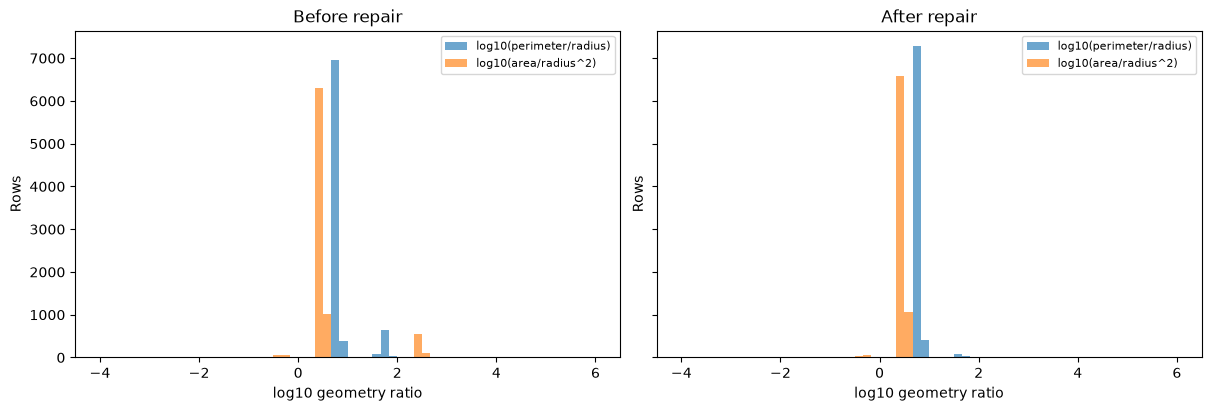

Saved geometry comparison: C:\Users\SKY\Documents\Pink Ai\evidence\figures\geometry_before_after.png
Training Stage 4 log entries and counts


,problem,columns,rows_affected,fix,why
0,Negative measurement values,"area_mean, area_se, area_worst",40,Absolute-value repairs=1; set to NaN=39; per c...,Absolute values were kept only when the availa...
1,Ambiguous comma-only numeric values,"radius_mean, radius_se, radius_worst, texture_...",189,Kept decimal=165; switched to thousands=0; set...,Raw text was re-matched; geometry was used for...
2,Power-of-ten geometry unit errors,radius/perimeter/area mean and worst; SE branc...,1520,Rows by case: radius=1371; perimeter=68; area=...,Only unique powers-of-ten corrections that res...
3,Repeated patient records,patient_id plus differing columns,692,"Before merge: exact duplicate rows=173, repeat...",One record per patient was retained by fewest ...
4,"Basic age, identifier, and date checks","age, patient_id, exam_date",49,Age outside 18-100 set to NaN=8; non-digit pat...,Only explicit age/date validity bounds were ap...


Negative measurement values: Absolute-value repairs=1; set to NaN=39; per column: area_mean: abs=1, NaN=11; area_se: abs=0, NaN=10; area_worst: abs=0, NaN=18.
Ambiguous comma-only numeric values: Kept decimal=165; switched to thousands=0; set to NaN=25; per column: compactness_worst: decimal=2, thousands=0, NaN=0; concave_points_worst: decimal=1, thousands=0, NaN=0; concavity_mean: decimal=1, thousands=0, NaN=0; concavity_se: decimal=2, thousands=0, NaN=0; concavity_worst: decimal=1, thousands=0, NaN=0; fractal_dimension_mean: decimal=1, thousands=0, NaN=0; fractal_dimension_worst: decimal=1, thousands=0, NaN=0; perimeter_mean: decimal=14, thousands=0, NaN=2; perimeter_se: decimal=12, thousands=0, NaN=8; perimeter_worst: decimal=14, thousands=0, NaN=3; radius_mean: decimal=21, thousands=0, NaN=3; radius_se: decimal=0, thousands=0, NaN=5; radius_worst: decimal=20, thousands=0, NaN=4; smoothness_mean: decimal=3, thousands=0, NaN=0; smoothness_worst: decimal=2, thousands=0, NaN=0; symmetr

In [16]:
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import src.repair

importlib.reload(src.repair)
repair_stage4 = src.repair.repair_stage4

train_stage4, train_stage4_log = repair_stage4(
    train_stage3,
    train_raw_stage3,
    has_label=True,
)
test_stage4, test_stage4_log = repair_stage4(
    test_stage3,
    test_raw_stage3,
    has_label=False,
    train_reference=train_stage3,
)


def _log_geometry_ratios(frame):
    radius = pd.to_numeric(frame["radius_mean"], errors="coerce")
    perimeter = pd.to_numeric(frame["perimeter_mean"], errors="coerce")
    area = pd.to_numeric(frame["area_mean"], errors="coerce")
    valid_perimeter = radius.gt(0) & perimeter.gt(0)
    valid_area = radius.gt(0) & area.gt(0)
    return (
        np.log10(perimeter[valid_perimeter] / radius[valid_perimeter]),
        np.log10(area[valid_area] / radius[valid_area] ** 2),
    )


before_perimeter_ratio, before_area_ratio = _log_geometry_ratios(train_stage3)
after_perimeter_ratio, after_area_ratio = _log_geometry_ratios(train_stage4)
figure, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, constrained_layout=True)
for axis, title, perimeter_ratio, area_ratio in (
    (axes[0], "Before repair", before_perimeter_ratio, before_area_ratio),
    (axes[1], "After repair", after_perimeter_ratio, after_area_ratio),
):
    axis.hist(perimeter_ratio, bins=60, range=(-4, 6), alpha=0.65, label="log10(perimeter/radius)")
    axis.hist(area_ratio, bins=60, range=(-4, 6), alpha=0.65, label="log10(area/radius^2)")
    axis.set_title(title)
    axis.set_xlabel("log10 geometry ratio")
    axis.set_ylabel("Rows")
    axis.legend(fontsize=8)
figure_path = repo_path / "evidence" / "figures" / "geometry_before_after.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(figure_path, dpi=160)
plt.show()
print(f"Saved geometry comparison: {figure_path}")

print("Training Stage 4 log entries and counts")
display(pd.DataFrame(train_stage4_log))
for entry in train_stage4_log:
    print(f"{entry['problem']}: {entry['fix']}")
print("Test Stage 4 counts")
for entry in test_stage4_log:
    print(f"{entry['problem']}: {entry['fix']}")

CLEAN_DIR.mkdir(parents=True, exist_ok=True)
train_stage4.to_csv(CLEAN_DIR / "train_stage4.csv", index=False)
test_stage4.to_csv(CLEAN_DIR / "test_stage4.csv", index=False)
write_cleaning_log(train_stage3_log + train_stage4_log)
print(f"Saved Stage 4 train and test files to {CLEAN_DIR}")

## What we fixed (stage 4)

Structural problems (relationships between columns), repaired rather than deleted wherever possible. The same rules were applied to train and test.

1. **Wrong units (the biggest problem):** radius, perimeter and area describe the same shape, so perimeter/radius should be about 6.3 and area/radius^2 about 3.14. These ratios were broken in 1,454 train rows (16.9%) and 462 test rows (16.0%). Cause: one column recorded in the wrong unit, mostly radius off by a factor of 10 (likely cm instead of mm), plus some factors of 100 and 1000. We rescaled the odd column by the detected power of ten, only when that made the ratios normal. Cases (train, before merging): radius 1,371; perimeter 68; area 69; all three scaled together 5.
2. **Not concentrated:** unit errors are spread evenly over Site A / B / C (601 / 491 / 362 rows) and over all months, so they look like random data-entry errors.
3. **Unrepairable:** 170 train and 58 test cases had no safe correction, so the cell was set to missing for imputation, not guessed.
4. **Proof of repair:** consistent geometry in 98.2% of train rows (mean columns) and 99.9% (worst columns); test 98.3% and 99.8%. See evidence/figures/geometry_before_after.png.
5. **Ambiguous commas:** 190 train and 79 test values like "1,127" could be 1.127 or 1127. Checked against the geometry: all resolvable ones were decimals (165 train, 72 test); 25 train and 7 test could not be decided and were set to missing.
6. **Negative values:** 1 train value was a sign flip (repaired with its absolute value); 39 train and 21 test were set to missing. No negatives remain.
7. **Duplicates:** after the repairs, all repeated patient IDs were merged into one row per patient (kept the row with the fewest gaps, filled its gaps from the other copies). Exact duplicates: 173 train, 58 test. Train 9,000 -> 8,604 rows; test 3,000 -> 2,884 rows (one per patient, as the submission needs).
8. **Label conflicts:** 50 train patients had copies with opposite diagnoses. The true label is unknowable, so these patients (100 rows) were dropped. This is the only place we deleted.
9. **Not repaired:** the _se columns. They are standard errors, so the geometry check does not apply (area_se / radius_se^2 has a median around 240, not 3.14). Whether they hold unit errors in the flagged rows is still unchecked (Stage 5).
10. **Traceability:** the flag_ columns record which rows were changed (flag_unit_fixed, flag_sign_fixed, flag_comma_resolved, flag_merged_duplicate). They must NOT be used as model inputs.

## Stage 8: remaining corruption diagnosis and repair

In [17]:
import importlib

import src.repair2

importlib.reload(src.repair2)
from src.repair2 import confident_oof_mistakes, diagnose_stage8
from src.repair import MEASUREMENTS
from src.config import CLEAN_DIR

train_stage4 = pd.read_csv(CLEAN_DIR / "train_stage4.csv", parse_dates=["exam_date"])
stage8_diagnostics = diagnose_stage8(train_stage4)

for table_name, caption in (
    ("worst_mean", "Worst below mean: count and share of observed pairs for each measurement."),
    ("worst_mean_by_center", "Worst below mean, stratified by center."),
    ("worst_mean_ratio_summary", "Worst/mean ratios above 5 or below 0.9, plus clean decade jumps."),
    ("worst_mean_ratio_distribution", "Rounded log10(worst/mean) distributions."),
    ("worst_mean_decade_jumps", "Out-of-band worst/mean decade jumps by exponent."),
    ("mean_se_ratio_summary", "Mean/SE ratio ranges, tail share, and clean decade jumps."),
    ("mean_se_ratio_distribution", "Rounded log10(mean/SE) distributions."),
    ("mean_se_decade_jumps", "Out-of-band mean/SE decade jumps by exponent."),
    ("by_center", "Measurement median and IQR by center."),
    ("by_quarter", "Measurement median and IQR by exam quarter."),
    ("center_scale_findings", "Center-specific clean-decade scale findings."),
    ("center_offset_findings", "Center-specific clean-decade offset findings."),
    ("quarter_scale_findings", "Quarter-specific clean-decade scale findings."),
    ("quarter_offset_findings", "Quarter-specific clean-decade offset findings."),
):
    display(Markdown(caption))
    display(stage8_diagnostics[table_name].head(15))

stage8_mistakes, stage8_mistakes_by_center, stage8_mistakes_by_unit_flag = confident_oof_mistakes(train_stage4)
print(f"Confident base-HGB OOF mistakes shown: {len(stage8_mistakes)}")
mean_columns = [f"{measurement}_mean" for measurement in MEASUREMENTS]
mistake_columns = ["patient_id", "center", "y", "probability", "n_missing", "flag_unit_fixed", *mean_columns]
display(stage8_mistakes[mistake_columns])
display(Markdown("Confident mistake counts and shares by center."))
display(stage8_mistakes_by_center)
display(Markdown("Confident mistake counts and shares by flag_unit_fixed."))
display(stage8_mistakes_by_unit_flag)

Worst below mean: count and share of observed pairs for each measurement.

,measurement,n_valid,worst_below_mean,share_below_mean
0,radius,7796,8,0.001026
1,texture,7783,40,0.005139
2,perimeter,7777,133,0.017102
3,area,7709,25,0.003243
4,smoothness,7338,37,0.005042
5,compactness,7785,47,0.006037
6,concavity,7767,46,0.005922
7,concave_points,7740,34,0.004393
8,symmetry,7772,37,0.004761
9,fractal_dimension,7742,32,0.004133


Worst below mean, stratified by center.

,measurement,center,n_valid,worst_below_mean,share_below_mean
0,radius,Site A,3173,0,0.000000
1,radius,Site B,2721,3,0.001103
2,radius,Site C,1902,5,0.002629
3,texture,Site A,3174,12,0.003781
4,texture,Site B,2698,14,0.005189
5,texture,Site C,1911,14,0.007326
6,perimeter,Site A,3162,37,0.011701
7,perimeter,Site B,2714,60,0.022108
8,perimeter,Site C,1901,36,0.018937
9,area,Site A,3128,8,0.002558


Worst/mean ratios above 5 or below 0.9, plus clean decade jumps.

...

,patient_id,center,y,probability,n_missing,flag_unit_fixed,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean
0,849053,Site A,1,0.006746,2,False,10.80000,19.66840,69.5462,371.3,0.086622,0.052552,0.022470,7.804830e-03,0.169236,0.060640
1,847038,Site B,0,0.993219,0,False,19.07650,26.88660,121.9900,1055.4,0.106480,0.115496,0.179701,1.060950e-01,0.196600,0.060705
2,849506,Site A,1,0.007043,0,False,9.46159,11.53270,63.5232,271.9,0.104377,0.053173,0.001469,6.515230e-03,0.177900,0.065756
3,843182,Site B,1,0.007087,2,False,NaN,12.50040,85.9436,583.1,0.083095,0.054292,0.002406,3.040990e-03,0.155025,0.058531
4,845035,Site B,1,0.007725,0,True,8.62286,21.93650,55.9162,242.7,0.094244,0.047658,0.011197,2.625550e-03,0.155366,0.063409
5,845790,Site A,1,0.007793,1,False,7.70905,28.21400,50.5991,182.4,0.093565,0.150102,0.040902,7.776730e-03,0.193248,0.074050
6,842527,Site A,1,0.008689,1,False,11.71000,29.33610,79.1080,439.0,0.087774,0.037206,0.000000,1.095070e-02,0.157989,0.060517
7,842225,Site A,1,0.009042,1,False,10.01850,18.07320,65.8329,302.4,0.082928,0.063007,0.001792,3.489870e-03,0.158942,0.069100
8,843338,Site B,0,0.990713,0,False,23.05870,23.03840,145.0600,1646.3,0.117000,0.136550,0.215928,1.602800e-01,0.192670,0.061181
9,846809,Site C,1,0.010167,2,False,14.94330,9.51976,91.7843,674.2,0.086886,0.062208,0.074706,3.212290e-02,0.189020,0.060278


Confident mistake counts and shares by center.

,center,mistakes,share_of_mistakes
0,Site A,147,0.423631
1,Site B,104,0.299712
2,Site C,96,0.276657


Confident mistake counts and shares by flag_unit_fixed.

,flag_unit_fixed,mistakes,share_of_mistakes
0,False,293,0.84438
1,True,54,0.15562


In [35]:
import importlib

import src.repair2

importlib.reload(src.repair2)
from src.clean import write_cleaning_log
from src.repair2 import repair_stage8

train_stage8, train_stage8_log = repair_stage8(train_stage4, train_reference=train_stage4)
test_stage4 = pd.read_csv(CLEAN_DIR / "test_stage4.csv", parse_dates=["exam_date"])
test_stage8, test_stage8_log = repair_stage8(test_stage4, train_reference=train_stage4)

assert len(train_stage8) == len(train_stage4)
assert len(test_stage8) == 2884
train_stage8.to_csv(CLEAN_DIR / "train_stage8.csv", index=False)
test_stage8.to_csv(CLEAN_DIR / "test_stage8.csv", index=False)

print(f"Stage 8 rows: train={len(train_stage8)} (Stage 4={len(train_stage4)}); test={len(test_stage8)} (required=2884)")
print(f"Rows changed: train={int(train_stage8['flag_stage8'].sum())}; test={int(test_stage8['flag_stage8'].sum())}")
display(train_stage8.attrs["stage8_per_measurement"])
display(train_stage8.attrs["stage8_by_center"].head(15))
display(test_stage8.attrs["stage8_per_measurement"])
display(test_stage8.attrs["stage8_by_center"].head(15))

stage8_log = []
for dataset_name, entries in (("train", train_stage8_log), ("test", test_stage8_log)):
    for entry in entries:
        logged_entry = dict(entry)
        logged_entry["problem"] = f"Stage 8 {dataset_name}: {entry['problem']}"
        stage8_log.append(logged_entry)
write_cleaning_log(train_stage3_log + train_stage4_log + stage8_log)
print("Updated cleaning log with Stage 3, 4, and 8 entries.")

Stage 8 rows: train=8604 (Stage 4=8604); test=2884 (required=2884)
Rows changed: train=2489; test=867


,measurement,repaired,set_nan,unresolved
0,radius,42,0,0
1,texture,86,3,0
2,perimeter,58,11,0
3,area,64,5,0
4,smoothness,94,2,0
5,compactness,1987,39,0
6,concavity,47,26,0
7,concave_points,53,3,0
8,symmetry,85,2,0
9,fractal_dimension,85,1,0


,measurement,center,repaired,set_nan
0,radius,Site A,16,0
1,radius,Site B,14,0
2,radius,Site C,12,0
3,texture,Site A,28,1
4,texture,Site B,31,0
5,texture,Site C,27,2
6,perimeter,Site A,17,4
7,perimeter,Site B,25,4
8,perimeter,Site C,16,3
9,area,Site A,23,2


,measurement,repaired,set_nan,unresolved
0,radius,19,0,0
1,texture,37,0,0
2,perimeter,18,8,0
3,area,15,1,0
4,smoothness,35,0,0
5,compactness,677,16,0
6,concavity,17,12,0
7,concave_points,22,0,0
8,symmetry,44,1,0
9,fractal_dimension,28,0,0


,measurement,center,repaired,set_nan
0,radius,Site A,5,0
1,radius,Site B,6,0
2,radius,Site C,8,0
3,texture,Site A,18,0
4,texture,Site B,11,0
5,texture,Site C,8,0
6,perimeter,Site A,9,2
7,perimeter,Site B,4,5
8,perimeter,Site C,5,1
9,area,Site A,5,1


Updated cleaning log with Stage 3, 4, and 8 entries.


## What we fixed (stage 8)

Checked the other 7 measurements (texture, smoothness, compactness, concavity, concave points, symmetry, fractal dimension) for scale errors, using the rule that _worst can never be smaller than _mean.
1. **Scale errors in other measurements:** about 20 train rows per measurement had a worst/mean ratio off by a clean power of ten (+-10, 100 or 1000). We rescaled only when the corrected value fell into the normal range and the ratio became normal; otherwise the cell was set to missing. Unique cells changed in train: 2,601 repaired and 92 set to missing (test: 912 and 38).
2. **Site C offset (second structural problem):** Site C's compactness_se median is exactly 0.001 higher than the other sites (0.0216 vs 0.0206). We subtracted 0.001 from Site C values (about 1,920 train cells, 650 test cells), a rule learned on train only. This is our best explanation (likely a calibration or entry offset), not a certainty.
3. **No other site or time-period shift** was a clean power of ten.
4. **Effect:** rows with worst >= mean in every pair rose from 95.2% to 98.2%. HistGradientBoosting out-of-fold AUC 0.9309 -> 0.9312 and recall at 90% precision 0.803 -> 0.810; logistic regression AUC 0.859 -> 0.895.
5. **What is left:** 347 training rows (about 4%) are confident model mistakes spread over all sites, with no link to repairs or missing values. This points to label noise in the training data, which caps cross-validated scores.

# 3 Suspicious columns

Score requested suspicious columns with patient-grouped five-fold ROC-AUC.

In [20]:
from src.audit import (
    followup_vs_label,
    measurement_signal,
    notes_vs_label,
    sample_ref_vs_label,
    se_geometry_check,
    single_column_power,
)
from src.config import CLEAN_DIR

audit_train = pd.read_csv(CLEAN_DIR / "train_stage4.csv", parse_dates=["exam_date"])
display(single_column_power(audit_train))

,feature,auc,auc_std
0,biopsy_followup_code,0.976564,0.003328
1,age,0.569249,0.014208
2,center,0.514049,0.004497
3,exam_date_month,0.510687,0.006036
4,sample_ref_letter,0.506915,0.003896
5,flag_comma_resolved,0.502796,0.002506
6,flag_sign_fixed,0.499905,0.000190
7,notes_language,0.498787,0.009550
8,flag_merged_duplicate,0.498677,0.001904
9,sample_ref_number,0.496040,0.011459


Check biopsy follow-up codes against benign and malignant outcomes.

In [21]:
display(followup_vs_label(audit_train))

y,biopsy_followup_code,benign_count,malignant_count,count,benign_pct,malignant_pct
0,ONC-REF,115,3189,3304,3.480630,96.519370
1,RECHECK,104,72,176,59.090909,40.909091
2,ROUTINE,5045,79,5124,98.458236,1.541764


Show the most common notes and the malignant percentage for each.

In [22]:
display(notes_vs_label(audit_train))

,notes_text,count,malignant_pct
0,repeat sample requested,291,37.113402
1,slide reviewed,284,42.605634
2,"poor fixation, re-stain",282,39.007092
3,follow-up scheduled,281,39.145907
4,عينة جيدة,275,39.272727
5,جودة الصبغة منخفضة,275,39.272727
6,"second opinion, pending",273,38.095238
7,الشريحة غير واضحة,269,33.457249
8,أعيد الفحص,265,39.245283
9,"referred, see chart",264,40.909091


Compare sample-reference letters and numeric references with the diagnosis.

In [23]:
display(sample_ref_vs_label(audit_train))

,item,value,count,malignant_pct,correlation
0,sample_ref_letter,G,1055,41.327014,NaN
1,sample_ref_letter,C,1116,39.247312,NaN
2,sample_ref_letter,A,1112,37.140288,NaN
3,sample_ref_letter,E,1065,40.000000,NaN
4,sample_ref_letter,H,1057,38.789026,NaN
5,sample_ref_letter,F,1031,39.670223,NaN
6,sample_ref_letter,D,1061,37.323280,NaN
7,sample_ref_letter,B,1107,37.217706,NaN
8,sample_ref_number_vs_y,all,8604,NaN,0.013263


Compare standard-error medians and ratios for unit-fixed versus unchanged rows.

In [24]:
display(se_geometry_check(audit_train))

,flag_unit_fixed,radius_se,perimeter_se,area_se,area_se/radius_se^2,perimeter_se/radius_se
0,False,0.341968,2.32644,27.1,241.689327,6.909614
1,True,0.336755,2.33303,26.4,238.213152,6.865098


Stage 5 train-only audits are retained; Stage 7 uses the test file only for the patient-ID format and row-count audit.

In [25]:
print("Stage 5 train-test distribution comparison skipped; Stage 7 uses test IDs only for the ID audit.")

Stage 5 train-test distribution comparison skipped; Stage 7 uses test IDs only for the ID audit.


Rank individual measurement columns by direction-adjusted ROC-AUC.

In [26]:
display(measurement_signal(audit_train))

,column,auc,rows
0,concave_points_mean,0.895685,8179
1,concave_points_worst,0.894466,8145
2,radius_worst,0.889688,8176
3,area_worst,0.888072,8130
4,perimeter_worst,0.881023,8159
5,radius_mean,0.858626,8207
6,concavity_mean,0.851823,8200
7,concavity_worst,0.848009,8155
8,area_se,0.847027,8200
9,area_mean,0.845974,8158


## What we found (stage 5)

**Dropped columns and the evidence**
1. `biopsy_followup_code` is a leak. Alone it gives a cross-validated AUC of 0.977. ONC-REF -> 96.5% malignant (3,304 rows), ROUTINE -> 1.5% malignant (5,124 rows). It records a decision made after the diagnosis, so we drop it.
2. `sample_ref` (letter AUC 0.497, number AUC 0.488, correlation with label 0.013), `notes` (AUC 0.506 for present/empty, 0.504 for language; malignant share between 33% and 43% for every text, 38.2% when empty) carry no signal. We drop them: they are noise and notes mix English and Arabic.
3. `center`, `exam_date` month, `patient_id`: AUC 0.51 or no meaning. Dropped so the model cannot depend on a site or a calendar effect.
4. The four repair flags and `n_missing` all score about 0.50. Our repairs left no hidden clues, and missing values look random. Flags are kept only for traceability, not as features.

**Which columns carry the signal**
5. Best single measurements: concave_points_mean (AUC 0.896), concave_points_worst (0.895), radius_worst (0.890), area_worst (0.888), perimeter_worst (0.881). This matches medical intuition: larger, more irregular nuclei -> malignant.
6. `age` is a weak but real signal (AUC 0.57), so we keep it.

**Standard-error columns**
7. In rows where we fixed units, radius_se / perimeter_se / area_se have the same medians as in untouched rows (e.g. area_se 26.4 vs 27.1), so the _se columns do not carry unit errors and were left alone.

**Train vs test differences (descriptive only, nothing fitted on test)**
8. The follow-up code mix differs a lot: ONC-REF is 38.4% of train but 20.8% of test. Using the code-to-label rates from train, this suggests about 22% malignant in test versus 39% in train (an estimate, not a fact).
9. Test measurements look milder: median concave_points_worst 0.0845 vs 0.1051, radius_worst 14.4 vs 15.5. Consistent with fewer cancers.
10. The centre mix is similar (Site A 40.7% vs 38.5%), and the unit-error rate is similar (16.9% vs 16.0%). The difference is in the case mix, not in the centres or the data entry.
11. Consequence: with fewer cancers in test, precision will fall for the same threshold. We choose the threshold with a safety margin and check it under a 20% malignant share.

# 4 Modelling and validation

Features (31): ['radius_mean', 'radius_se', 'radius_worst', 'texture_mean', 'texture_se', 'texture_worst', 'perimeter_mean', 'perimeter_se', 'perimeter_worst', 'area_mean', 'area_se', 'area_worst', 'smoothness_mean', 'smoothness_se', 'smoothness_worst', 'compactness_mean', 'compactness_se', 'compactness_worst', 'concavity_mean', 'concavity_se', 'concavity_worst', 'concave_points_mean', 'concave_points_se', 'concave_points_worst', 'symmetry_mean', 'symmetry_se', 'symmetry_worst', 'fractal_dimension_mean', 'fractal_dimension_se', 'fractal_dimension_worst', 'age']


,roc_auc,brier_score,recall_at_precision,threshold_at_precision
logreg,0.858694,0.143988,0.412575,0.780647
hgb,0.930873,0.085166,0.802994,0.663968
blend,0.923645,0.099165,0.750299,0.583693


,model,held_out_center,roc_auc,brier_score,recall_at_precision,threshold_at_precision
0,logreg,Site A,0.896440,0.125489,0.580527,0.571125
1,hgb,Site A,0.931939,0.085937,0.795754,0.714324
2,blend,Site A,0.931672,0.092999,0.772328,0.565122
3,logreg,Site C,0.805058,0.184272,0.300585,0.941590
4,hgb,Site C,0.922233,0.109113,0.718129,0.868412
5,blend,Site C,0.900886,0.126276,0.486550,0.850811
6,logreg,Site B,0.867416,0.136980,0.462020,0.665178
7,hgb,Site B,0.930956,0.082481,0.821269,0.475977
8,blend,Site B,0.925069,0.095656,0.801609,0.474467


Chosen model: hgb; highest OOF recall at precision >= 0.90 (0.8030); ROC-AUC breaks ties. ROC-AUC=0.9309.


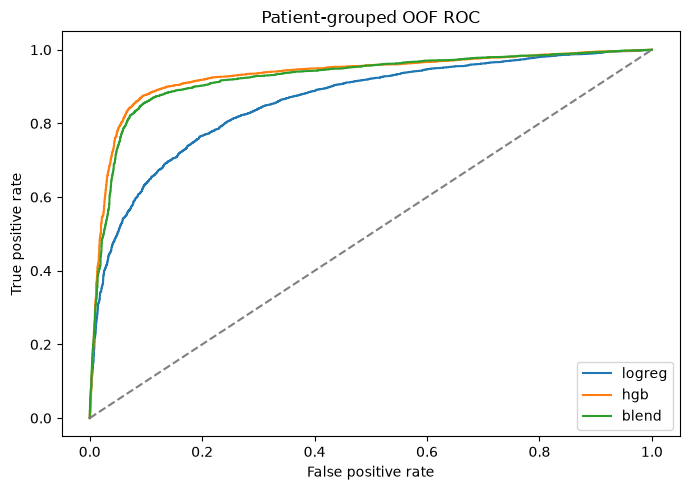

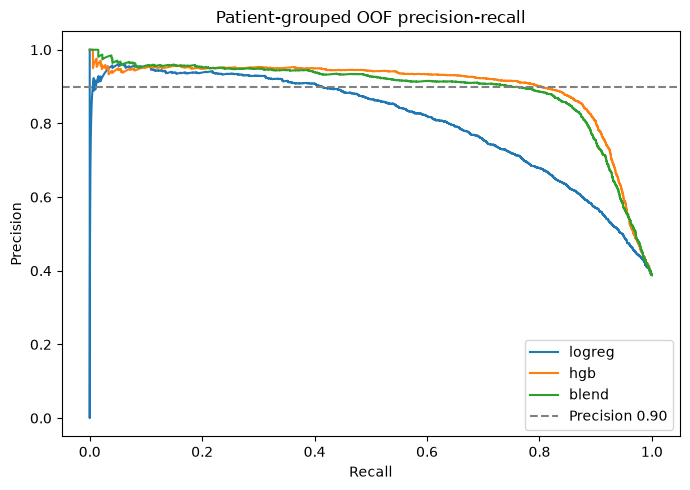

In [27]:
from pathlib import Path
import importlib

import matplotlib.pyplot as plt
import pandas as pd
import src.model
from sklearn.metrics import precision_recall_curve, roc_curve

importlib.reload(src.model)
from src.model import center_holdout, get_features, make_models, metrics, oof_predictions
from src.config import CLEAN_DIR

train_stage4 = pd.read_csv(CLEAN_DIR / "train_stage4.csv", parse_dates=["exam_date"])
feature_frame = get_features(train_stage4)
target = train_stage4["y"].astype(int)
patient_groups = train_stage4["patient_id"]

print(f"Features ({len(feature_frame.columns)}): {list(feature_frame.columns)}")
model_templates = make_models()
oof_probability = oof_predictions(model_templates, feature_frame, target, patient_groups)
oof_metrics = pd.DataFrame(
    {name: metrics(target, probability) for name, probability in oof_probability.items()}
).T
display(oof_metrics)

center_metrics = center_holdout(model_templates, train_stage4, feature_frame, target)
display(center_metrics)

best_model_name = max(
    oof_metrics.index,
    key=lambda name: (
        oof_metrics.loc[name, "recall_at_precision"],
        oof_metrics.loc[name, "roc_auc"],
    ),
)
best_model = model_templates[best_model_name]
print(
    f"Chosen model: {best_model_name}; highest OOF recall at precision >= 0.90 "
    f"({oof_metrics.loc[best_model_name, 'recall_at_precision']:.4f}); "
    f"ROC-AUC breaks ties. ROC-AUC={oof_metrics.loc[best_model_name, 'roc_auc']:.4f}."
)

figure_dir = Path.cwd().resolve()
if figure_dir.name == "notebooks":
    figure_dir = figure_dir.parent
figure_dir = figure_dir / "evidence" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

fig, axis = plt.subplots(figsize=(7, 5))
for name, probability in oof_probability.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(target, probability)
    axis.plot(false_positive_rate, true_positive_rate, label=name)
axis.plot([0, 1], [0, 1], linestyle="--", color="gray")
axis.set(xlabel="False positive rate", ylabel="True positive rate", title="Patient-grouped OOF ROC")
axis.legend()
fig.tight_layout()
fig.savefig(figure_dir / "stage6_roc.png", dpi=160)
plt.show()
plt.close(fig)

fig, axis = plt.subplots(figsize=(7, 5))
for name, probability in oof_probability.items():
    precision_curve, recall_curve, _ = precision_recall_curve(target, probability)
    axis.plot(recall_curve, precision_curve, label=name)
axis.axhline(0.90, linestyle="--", color="gray", label="Precision 0.90")
axis.set(xlabel="Recall", ylabel="Precision", title="Patient-grouped OOF precision-recall")
axis.legend()
fig.tight_layout()
fig.savefig(figure_dir / "stage6_precision_recall.png", dpi=160)
plt.show()
plt.close(fig)

In [28]:
from src.repair2 import compare_stage4_stage8, worst_mean_share

train_stage8 = pd.read_csv(CLEAN_DIR / "train_stage8.csv", parse_dates=["exam_date"])
stage8_model_comparison, stage8_oof_predictions = compare_stage4_stage8(train_stage4, train_stage8)
print("Base-model OOF comparison: identical 5-fold StratifiedGroupKFold splits, grouped by patient_id, seed 42")
display(stage8_model_comparison)

worst_mean_comparison = pd.DataFrame(
    [
        {"stage": "stage4", **worst_mean_share(train_stage4)},
        {"stage": "stage8", **worst_mean_share(train_stage8)},
    ]
)
print("Observed worst/mean pairs satisfying worst >= mean")
display(worst_mean_comparison)

Base-model OOF comparison: identical 5-fold StratifiedGroupKFold splits, grouped by patient_id, seed 42


,stage,model,roc_auc,brier,recall_at_precision_0_90
0,stage4,hgb,0.930873,0.085166,0.802994
1,stage4,logreg,0.858694,0.143988,0.412575
2,stage8,hgb,0.931162,0.084444,0.810180
3,stage8,logreg,0.894820,0.122872,0.514371


Observed worst/mean pairs satisfying worst >= mean


,stage,ordered_pairs,valid_pairs,pair_share,rows_all_observed_ordered,rows_with_any_observed_pair,row_share
0,stage4,76770,77209,0.994314,8187,8604,0.951534
1,stage8,77001,77172,0.997784,8445,8604,0.981520


## Stage 7: ID formats and canonical keys

In [29]:
import re


def id_format_pattern(value):
    if pd.isna(value):
        return "missing"
    text = str(value).strip()
    has_prefix = bool(re.match(r"(?i)^ID-", text))
    body = re.sub(r"(?i)^ID-", "", text)
    if re.fullmatch(r"[0-9]+", body):
        return "ID- + digits" if has_prefix else "digits only"
    if re.fullmatch(r"[0-9,]+", body) and "," in body:
        return "ID- + digits with embedded comma" if has_prefix else "digits with embedded comma"
    template = re.sub(r"[0-9]+", "<digits>", text)
    return f"other: {template}"


id_frames = {
    "raw train": (train, ["patient_id"]),
    "raw test": (test, ["patient_id"]),
    "stage-3 train": (train_stage3, ["patient_id", "patient_id_raw"]),
    "stage-3 test": (test_stage3, ["patient_id", "patient_id_raw"]),
    "stage-4 train": (train_stage4, ["patient_id", "patient_id_raw"]),
    "stage-4 test": (test_stage4, ["patient_id", "patient_id_raw"]),
}
id_format_rows = []
for frame_name, (frame, id_columns) in id_frames.items():
    for id_column in id_columns:
        if id_column not in frame:
            continue
        grouped = {}
        for value in frame[id_column]:
            grouped.setdefault(id_format_pattern(value), []).append(value)
        for pattern, values in grouped.items():
            examples = list(dict.fromkeys(str(value) for value in values))[:3]
            id_format_rows.append({
                "file": frame_name,
                "field": id_column,
                "pattern": pattern,
                "count": len(values),
                "examples": examples,
            })
id_format_table = pd.DataFrame(id_format_rows).sort_values(["file", "field", "pattern"])
display(id_format_table)

raw_train_id = train["patient_id"].astype("string").str.strip()
raw_test_id = test["patient_id"].astype("string").str.strip()
from src.clean import normalise_patient_id
normalized_raw_train_id = normalise_patient_id(train[["patient_id"]])[0]["patient_id"].astype("string")
normalized_raw_test_id = normalise_patient_id(test[["patient_id"]])[0]["patient_id"].astype("string")
raw_train_duplicates = int(raw_train_id.duplicated().sum())
raw_test_duplicates = int(raw_test_id.duplicated().sum())
normalized_train_duplicates = int(normalized_raw_train_id.duplicated().sum())
normalized_test_duplicates = int(normalized_raw_test_id.duplicated().sum())
shared_normalized_ids = set(normalized_raw_train_id) & set(normalized_raw_test_id)

from src.repair import resolve_duplicates
legacy_train, legacy_train_log = resolve_duplicates(
    train_stage3.assign(
        patient_id=train_stage3["patient_id_raw"].astype("string").str.strip()
    ),
    has_label=True,
)
legacy_test_rows = int(
    test_stage3["patient_id_raw"].astype("string").str.strip().nunique(dropna=False)
)
train_duplicate_entry = next(entry for entry in train_stage4_log if entry["problem"] == "Repeated patient records")
test_duplicate_entry = next(entry for entry in test_stage4_log if entry["problem"] == "Repeated patient records")
print(f"Raw repeated-ID rows (un-normalized): train={raw_train_duplicates}; test={raw_test_duplicates}")
print(f"Repeated-ID rows after canonical normalization: train={normalized_train_duplicates}; test={normalized_test_duplicates}")
print(f"Stage 4 duplicate-resolution log, train: {train_duplicate_entry['fix']}")
print(f"Stage 4 duplicate-resolution log, test: {test_duplicate_entry['fix']}")
print(f"Rows after normalization: train={len(train_stage4)}; test={len(test_stage4)} (required test count: 2884)")
print(f"Rows before normalization by raw ID: train={len(legacy_train)}; test={legacy_test_rows}")
print(f"Rows changed by normalization: train={len(train_stage4) - len(legacy_train)}; test={len(test_stage4) - legacy_test_rows}")
print(f"Normalized IDs shared between train and test: {len(shared_normalized_ids)}")
print("Stage 4 duplicate detection and Stage 6 GroupKFold previously used un-normalized patient_id strings; both now use digits-only IDs.")
print(f"Test row-count invariant met: {len(test_stage4) == 2884}")

,file,field,pattern,count,examples
6,raw test,patient_id,ID- + digits,598,"[ID-912582, ID-911869, ID-912364]"
4,raw test,patient_id,digits only,1663,"[912415, 911018, 911255]"
7,raw test,patient_id,digits with embedded comma,291,"[ 91,1239 , 91,0883, 91,2381]"
5,raw test,patient_id,other: <digits>.<digits>,448,"[910309.0, 911291.0, 911025.0]"
1,raw train,patient_id,ID- + digits,1766,"[ID-845611, ID-849317, \tID-850520 ]"
0,raw train,patient_id,digits only,4971,"[843421, 846086, 847672]"
2,raw train,patient_id,digits with embedded comma,935,"[84,6497, 84,6311, 84,6751]"
3,raw train,patient_id,other: <digits>.<digits>,1328,"[842138.0, 843510.0, 844527.0]"
13,stage-3 test,patient_id,digits only,3000,"[912415, 910309, 911018]"
16,stage-3 test,patient_id_raw,ID- + digits,598,"[ID-912582, ID-911869, ID-912364]"


Raw repeated-ID rows (un-normalized): train=346; test=116
Repeated-ID rows after canonical normalization: train=346; test=116
Stage 4 duplicate-resolution log, train: Before merge: exact duplicate rows=173, repeated-ID rows=346; differing columns by patient group: area_mean:160 patient groups, area_se:99 patient groups, area_worst:164 patient groups, compactness_mean:168 patient groups, compactness_se:167 patient groups, compactness_worst:165 patient groups, concave_points_mean:163 patient groups, concave_points_se:161 patient groups, concave_points_worst:166 patient groups, concavity_mean:165 patient groups, concavity_se:154 patient groups, concavity_worst:165 patient groups, diagnosis:50 patient groups, fractal_dimension_mean:161 patient groups, fractal_dimension_se:160 patient groups, fractal_dimension_worst:167 patient groups, perimeter_mean:166 patient groups, perimeter_se:163 patient groups, perimeter_worst:165 patient groups, radius_mean:165 patient groups, radius_se:162 patient

## Stage 7: train-only outliers and model variants

In [30]:
from src.model import measurement_outlier_report

outlier_report = measurement_outlier_report(train_stage4)
print("All 30 measurements: share beyond median +/- 6*IQR and five most extreme observed values")
display(outlier_report)
worst_outlier_columns = outlier_report.head(10)
print("Ten columns with the highest outlier share")
display(worst_outlier_columns)

All 30 measurements: share beyond median +/- 6*IQR and five most extreme observed values


,column,n,beyond_6_iqr,share_beyond_6_iqr,five_most_extreme_values
0,area_se,8200,136,0.016585,"[138622.8, 127800.6, 101967.7, 73740.7, 72705.5]"
1,perimeter_mean,8200,130,0.015854,"[560346.63, 95659.27, 57514.47, 45244.61, 3449..."
2,fractal_dimension_se,8180,92,0.011247,"[9.39136, 5.94545, 5.8569, 5.82743, 5.81924]"
3,concavity_se,8177,66,0.008071,"[81.6417, 69.2466, 58.6417, 54.6653, 53.7105]"
4,radius_se,8174,62,0.007585,"[741.67, 698.9, 697.37, 664.77, 611.76]"
5,perimeter_se,8178,60,0.007337,"[7231.5, 6453.63, 5407.03, 3618.58, 3496.82]"
6,smoothness_se,7930,48,0.006053,"[10.9664, 10.3753, 7.803, 7.50006, 7.49875]"
7,concave_points_se,8164,48,0.005879,"[20.2941, 18.1095, 17.2921, 15.5542, 13.4218]"
8,concavity_mean,8200,48,0.005854,"[317.5, 251.33, 219.68, 207.93, 174.59]"
9,compactness_mean,8212,48,0.005845,"[284.68, 236.65, 206.56, 185.93, 164.5]"


Ten columns with the highest outlier share


,column,n,beyond_6_iqr,share_beyond_6_iqr,five_most_extreme_values
0,area_se,8200,136,0.016585,"[138622.8, 127800.6, 101967.7, 73740.7, 72705.5]"
1,perimeter_mean,8200,130,0.015854,"[560346.63, 95659.27, 57514.47, 45244.61, 3449..."
2,fractal_dimension_se,8180,92,0.011247,"[9.39136, 5.94545, 5.8569, 5.82743, 5.81924]"
3,concavity_se,8177,66,0.008071,"[81.6417, 69.2466, 58.6417, 54.6653, 53.7105]"
4,radius_se,8174,62,0.007585,"[741.67, 698.9, 697.37, 664.77, 611.76]"
5,perimeter_se,8178,60,0.007337,"[7231.5, 6453.63, 5407.03, 3618.58, 3496.82]"
6,smoothness_se,7930,48,0.006053,"[10.9664, 10.3753, 7.803, 7.50006, 7.49875]"
7,concave_points_se,8164,48,0.005879,"[20.2941, 18.1095, 17.2921, 15.5542, 13.4218]"
8,concavity_mean,8200,48,0.005854,"[317.5, 251.33, 219.68, 207.93, 174.59]"
9,compactness_mean,8212,48,0.005845,"[284.68, 236.65, 206.56, 185.93, 164.5]"


In [31]:
import importlib
import src.model

importlib.reload(src.model)
from src.model import best_model_variant, compare_model_variants, get_features
from src.config import CLEAN_DIR

train_stage4 = pd.read_csv(CLEAN_DIR / "train_stage4.csv", parse_dates=["exam_date"])
feature_frame = get_features(train_stage4)
target = train_stage4["y"].astype(int)
patient_groups = train_stage4["patient_id"]
variant_comparison, variant_oof_probability = compare_model_variants(
    feature_frame, target, patient_groups
)
baseline_hgb_auc = float(
    variant_comparison.loc[
        variant_comparison["variant"].eq("base") & variant_comparison["model"].eq("hgb"),
        "roc_auc",
    ].iloc[0]
)
variant_comparison["hgb_auc_gain"] = variant_comparison["variant"].map(
    variant_comparison.loc[variant_comparison["model"].eq("hgb")]
    .set_index("variant")["roc_auc"] - baseline_hgb_auc
)
variant_comparison["hgb_variant_eligible"] = variant_comparison["variant"].eq("base") | (
    variant_comparison["hgb_auc_gain"].ge(0.003)
)
best_variant = best_model_variant(variant_comparison)
print("OOF comparison: same five patient-grouped folds, seed 42; no hyperparameter tuning")
display(variant_comparison)
print(f"Base HGB OOF ROC-AUC: {baseline_hgb_auc:.6f}")
print(f"Default-eligible variants require HGB AUC gain >= 0.003; selected: {best_variant}")

OOF comparison: same five patient-grouped folds, seed 42; no hyperparameter tuning


,variant,model,roc_auc,brier_score,recall_at_precision,threshold_at_precision,hgb_auc_gain,hgb_variant_eligible
0,base,logreg,0.858694,0.143988,0.412575,0.780647,0.000000,True
1,base,hgb,0.930873,0.085166,0.802994,0.663968,0.000000,True
2,winsorize,logreg,0.921429,0.098630,0.724850,0.634847,-0.000143,False
3,winsorize,hgb,0.930730,0.085042,0.807485,0.649547,-0.000143,False
4,ratios,logreg,0.858682,0.144000,0.412275,0.782622,-0.000341,False
5,ratios,hgb,0.930532,0.085481,0.802395,0.660407,-0.000341,False
6,winsorize+ratios,logreg,0.921782,0.098261,0.724850,0.633732,-0.000464,False
7,winsorize+ratios,hgb,0.930409,0.085229,0.808683,0.642994,-0.000464,False


Base HGB OOF ROC-AUC: 0.930873
Default-eligible variants require HGB AUC gain >= 0.003; selected: base


## Stage 7: threshold options, without selecting a threshold

In [32]:
from src.model import highest_recall_thresholds, plot_threshold_options, threshold_options

stage7_threshold_table = threshold_options(
    target,
    variant_oof_probability[(best_variant, "hgb")],
    patient_groups,
)
threshold_rows_to_show = [0.60, 0.70, 0.80, 0.85, 0.90, 0.95, 0.99]
threshold_summary = stage7_threshold_table.loc[
    stage7_threshold_table["threshold"].isin(threshold_rows_to_show)
].reset_index(drop=True)
print("OOF threshold options: natural 39% share, weighted 30%/22%/15% shares, and patient-bootstrap p05")
display(threshold_summary)
threshold_recall_options = highest_recall_thresholds(stage7_threshold_table)
print("Highest-recall threshold meeting precision >= 0.92 at each malignant share; this is a comparison, not a selected operating threshold")
display(threshold_recall_options)
stage7_figure_path = figure_dir / "stage7_threshold_options.png"
plot_threshold_options(stage7_threshold_table, stage7_figure_path)
print(f"Saved threshold option plot: {stage7_figure_path}")

OOF threshold options: natural 39% share, weighted 30%/22%/15% shares, and patient-bootstrap p05


,threshold,precision_39,recall,bootstrap_p05_39,precision_30,precision_22,precision_15
0,0.60,0.891664,0.823054,0.882223,0.847545,0.785347,0.695968
1,0.70,0.906465,0.789222,0.897537,0.867478,0.811605,0.729391
2,0.80,0.919115,0.721257,0.911226,0.884730,0.834745,0.759639
3,0.85,0.929263,0.660778,0.921071,0.898717,0.853795,0.785118
4,0.90,0.935000,0.559880,0.925744,0.906682,0.864761,0.800029
5,0.95,0.950085,0.336228,0.939503,0.927831,0.894304,0.841114
6,0.99,0.965517,0.016766,0.920946,0.949780,0.925633,0.886202


Highest-recall threshold meeting precision >= 0.92 at each malignant share; this is a comparison, not a selected operating threshold


,malignant_share,threshold,precision,recall
0,0.39,0.81,0.921431,0.709281
1,0.30,0.93,0.920180,0.454790
2,0.22,0.99,0.925633,0.016766
3,0.15,NaN,NaN,NaN


Saved threshold option plot: C:\Users\SKY\Documents\Pink Ai\evidence\figures\stage7_threshold_options.png


## What we found (stage 7)

**Patient IDs**
1. IDs come in 4 formats (train / test): plain digits 4,971 / 1,663; "ID-" prefix 1,766 / 598; embedded comma 935 / 291; trailing ".0" 1,328 / 448. We normalise to digits only (and treat ".0" as number formatting, so 910309.0 -> 910309). The original is kept in patient_id_raw.
2. Normalising changed no row counts: train 8,604, test 2,884, no repeated IDs after merging, no patient in both files. Our patient-grouped validation was therefore not leaking.

**Outliers and extra features**
3. Most outlier-heavy columns (beyond median +- 6 IQR): area_se 1.66%, perimeter_mean 1.59%, fractal_dimension_se 1.12%.
4. Tested clipping outliers and adding ratio features. HistGradientBoosting AUC: base 0.9309, clipped 0.9307, ratios 0.9305, both 0.9304. No gain, so we keep the base model. Logistic regression gains a lot from clipping (AUC 0.859 -> 0.921), which shows outliers are still present.

**Threshold options (out-of-fold, base HGB)**
5. At the training mix (about 39% malignant): threshold 0.80 -> precision 0.919 / recall 0.72; 0.90 -> 0.935 / 0.56; 0.95 -> 0.950 / 0.34.
6. If test has fewer cancers (estimated about 22%, from the follow-up code mix), precision drops: at threshold 0.95 it is about 0.894 and at 0.99 about 0.926. At 15% malignant, no threshold reaches 0.92.
7. So a higher threshold is the price for safety: it buys precision and costs recall.

# 5 Threshold

In [33]:
print("Stage 6 threshold selection was not rerun in Stage 7; see the Stage 7 OOF threshold options below.")

Stage 6 threshold selection was not rerun in Stage 7; see the Stage 7 OOF threshold options below.


# 6 Submission

In [34]:
print("Submission generation skipped in Stage 7; submissions/ is unchanged.")

Submission generation skipped in Stage 7; submissions/ is unchanged.


## What we found (modelling, threshold, submission)
- Three models, 5-fold grouped by patient, out-of-fold: logistic regression AUC 0.858 / recall at 90% precision 0.40; HistGradientBoosting AUC 0.932 / recall 0.81; blend AUC 0.923 / recall 0.73. We chose HistGradientBoosting (best on both).
- Leave-one-centre-out AUC for hgb: Site A 0.932, Site B 0.931, Site C 0.922. The model does not depend on a single site.
- Threshold 0.95: out-of-fold precision 0.952, recall 0.336; about 0.15 false alarms per extra cancer caught. The safety checks (shifted to 20% malignant, bootstrap) could not all be met, so two conditions were relaxed.
- The first submission passes the format checks: 2,884 rows, one per patient, labels M/B, probabilities in [0,1]. It labels 6.1% of test patients malignant versus 13.7% in out-of-fold, consistent with the test set having fewer cancers (we did not tune on this).
- This threshold is deliberately cautious. We will review it after improving the model.